# PhoBERT Level 3 — Cross-Attention giữa `text` và `quoted_text`

Kiến trúc (shared encoder, giữ nguyên split train/val/test của notebook Fusion trước):
- **Encoder dùng chung**: PhoBERT mã hóa `text` và `quoted_text` thành chuỗi token-level `H_t`, `H_q` (không chỉ lấy `[CLS]`).
- **Cross-attention hai chiều**:
  - `text → quote`: mỗi token của bình luận (query) nhìn vào các token của đoạn trích dẫn (key/value).
  - `quote → text`: ngược lại.
  - Mỗi khối gồm Multi-Head Attention + residual + LayerNorm + FFN + residual + LayerNorm.
- **Quote gate**: nếu không có quote (`quote_present = 0`) thì bỏ nhánh cross-attention, giữ biểu diễn gốc của text.
- **Pooling + Classifier**: `[CLS_text, mean(T2Q), mean(Q2T), mean(T2Q)*mean(Q2T), quote_present]` → MLP → 3 lớp (`clean`, `offensive`, `hate`).

Notebook đọc 3 file `train.csv / val.csv / test.csv` có sẵn (không chia lại), lưu checkpoint tốt nhất theo validation Macro-F1, báo cáo, confusion matrix, dự đoán test, phân tích theo nhóm có/không quote và so sánh với baseline Fusion.

In [1]:
import os, json, random, time, gc, hashlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

# ===== SỬA đường dẫn nếu cần (giữ NGUYÊN các file split đã dùng cho baseline) =====
DATA_PATH_TRAIN = "H:\\Data\\dataset\\train.csv"
DATA_PATH_VAL   = "H:\\Data\\dataset\\val.csv"
DATA_PATH_TEST  = "H:\\Data\\dataset\\test.csv"
OUT_DIR = "H:\\Data\\result\\phobert_cross_attention"  # output dir
TEXT_COL = "text"
QUOTE_COL = "quoted_text"
LABEL_COL = "lable"          # tự dò lable/label

MODEL_NAME = "vinai/phobert-base"
MAX_TEXT_LEN = 160
MAX_QUOTE_LEN = 96
BATCH_SIZE = 8               # CUDA OOM -> 4
EPOCHS = 5
ENCODER_LR = 2e-5
HEAD_LR = 1e-4               # lr lớn hơn cho cross-attention + classifier (khởi tạo ngẫu nhiên)
WEIGHT_DECAY = 0.01
DROPOUT = 0.30               # dropout classifier
ATTN_DROPOUT = 0.10
NUM_HEADS = 8
WARMUP_RATIO = 0.10

# Kết quả baseline Fusion (CLS) đã chạy trước đó, dùng để so sánh
BASELINE = {"model": "PhoBERT_SharedDualBranch_Fusion", "accuracy": 0.915138, "macro_f1": 0.911743, "weighted_f1": 0.914791}

os.makedirs(OUT_DIR, exist_ok=True)
SPLIT_DIR = os.path.join(OUT_DIR, "splits"); os.makedirs(SPLIT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda": print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 5090


## 1. Đọc CSV (giữ nguyên split)

In [2]:
def load_any(path):
    if path.endswith(".csv"): return pd.read_csv(path)
    if path.endswith((".xlsx", ".xls")): return pd.read_excel(path)
    if path.endswith((".jsonl", ".json")):
        try: return pd.read_json(path, lines=True)
        except ValueError: return pd.read_json(path)
    raise ValueError("Định dạng file không hỗ trợ")

train_df, val_df, test_df = load_any(DATA_PATH_TRAIN), load_any(DATA_PATH_VAL), load_any(DATA_PATH_TEST)

def find_column(df, candidates, role, required=True):
    for c in candidates:
        if c in df.columns: return c
    if required: raise ValueError(f"Không tìm thấy cột {role}. Cột hiện có: {list(df.columns)}")
    return None

for name, fr in [("train", train_df), ("val", val_df), ("test", test_df)]:
    if TEXT_COL not in fr.columns: raise ValueError(f"{name}: thiếu cột {TEXT_COL}")
    ls = find_column(fr, [LABEL_COL, "lable", "label", "label_new"], "nhãn")
    if ls != "label": fr["label"] = fr[ls]
    qs = find_column(fr, [QUOTE_COL, "quote_text", "quoted_text"], "trích dẫn", required=False)
    if qs is None: fr[QUOTE_COL] = ""
    elif qs != QUOTE_COL: fr[QUOTE_COL] = fr[qs]
    # Chấp nhận nhãn đầu vào dạng chữ (clean/offensive/hate) hoặc ID số (0/1/2).
    raw_labels = fr["label"].astype("string").str.strip().str.lower()
    label_map = {"clean": 0, "offensive": 1, "hate": 2}
    mapped = raw_labels.map(label_map)
    numeric = pd.to_numeric(raw_labels, errors="coerce")
    fr["label"] = mapped.where(mapped.notna(), numeric)
    if fr["label"].isna().any() or not set(fr["label"].astype(int).unique()).issubset({0, 1, 2}):
        bad = raw_labels[fr["label"].isna() | ~fr["label"].isin([0, 1, 2])].value_counts(dropna=False).to_dict()
        raise ValueError(f"{name}: nhãn không hợp lệ: {bad}. Nhãn cho phép: clean/offensive/hate hoặc 0/1/2")
    fr["label"] = fr["label"].astype(int)
    fr[TEXT_COL] = fr[TEXT_COL].fillna("").astype(str)
    fr[QUOTE_COL] = fr[QUOTE_COL].fillna("").astype(str)

# Dấu vân tay split: so với notebook baseline để chắc chắn dùng đúng dòng dữ liệu
def fingerprint(df):
    s = "\n".join((df[TEXT_COL] + "||" + df[QUOTE_COL] + "||" + df["label"].astype(str)).tolist())
    return hashlib.md5(s.encode("utf-8")).hexdigest()
fp = {n: fingerprint(d) for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
print("Split fingerprints:", fp)
json.dump(fp, open(os.path.join(SPLIT_DIR, "split_fingerprints.json"), "w"), indent=2)
for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d.to_csv(os.path.join(SPLIT_DIR, f"{n}_used.csv"), index=False, encoding="utf-8-sig")
    vc = d["label"].value_counts().reindex([0, 1, 2]).fillna(0).astype(int)
    hq = (d[QUOTE_COL].str.strip() != "").mean()
    print(f"{n:5s} n={len(d):6d} | clean={vc[0]} offensive={vc[1]} hate={vc[2]} | có quote={hq:.1%}")

Split fingerprints: {'train': '33f5ce48de33989e12c4301e57709d69', 'val': '9ae7a4f08f8a988604d338bf68ffb17c', 'test': '2489febfac2e463217f0a7ef6184c884'}
train n= 49231 | clean=24616 offensive=14769 hate=9846 | có quote=58.1%
val   n=  6153 | clean=3077 offensive=1846 hate=1230 | có quote=57.3%
test  n=  6156 | clean=3077 offensive=1847 hate=1232 | có quote=57.5%


## 2. Word segmentation với VnCoreNLP

In [3]:
import os
import pandas as pd
import py_vncorenlp

VNCORPUS_DIR = r"H:\\Data\\vncorenlp"

# Kiểm tra các file model
required_files = [
    os.path.join(VNCORPUS_DIR, "VnCoreNLP-1.2.jar"),
    os.path.join(VNCORPUS_DIR, "models", "wordsegmenter", "vi-vocab"),
    os.path.join(VNCORPUS_DIR, "models", "wordsegmenter", "wordsegmenter.rdr"),
]

for path in required_files:
    print("OK:" if os.path.isfile(path) else "MISSING:", path)

# Khởi tạo bộ tách từ
segmenter = py_vncorenlp.VnCoreNLP(
    annotators=["wseg"],
    save_dir=VNCORPUS_DIR
)

# Kiểm tra thử
print(segmenter.word_segment("Tôi đang xây dựng mô hình phân loại bình luận độc hại."))

# 4. Tách từ
def segment_text(v):
    if pd.isna(v):
        return ""

    v = str(v).strip()
    return " ".join(segmenter.word_segment(v)) if v else ""


# 5. Phân đoạn từng split và lưu cache
def segment_split(frame, split_name):
    frame = frame.reset_index(drop=True).copy()

    cache_path = os.path.join(
        OUT_DIR, f"segmented_{split_name}.csv"
    )

    if os.path.exists(cache_path):
        c = pd.read_csv(cache_path, keep_default_na=False)

        required_cols = {
            "text_original",
            "quote_original",
            "text_segmented",
            "quote_segmented"
        }

        ok = (
            len(c) == len(frame)
            and required_cols.issubset(c.columns)
            and c["text_original"].astype(str).tolist()
                == frame[TEXT_COL].astype(str).tolist()
            and c["quote_original"].astype(str).tolist()
                == frame[QUOTE_COL].astype(str).tolist()
        )

        if ok:
            frame["text_segmented"] = c["text_segmented"].astype(str).values
            frame["quote_segmented"] = c["quote_segmented"].astype(str).values
            print("Loaded cache:", split_name)
            return frame

        print("Cache không khớp, tạo lại:", split_name)

    frame["text_segmented"] = [
        segment_text(x) for x in frame[TEXT_COL]
    ]

    frame["quote_segmented"] = [
        segment_text(x) for x in frame[QUOTE_COL]
    ]

    pd.DataFrame({
        "text_original": frame[TEXT_COL].astype(str),
        "quote_original": frame[QUOTE_COL].astype(str),
        "text_segmented": frame["text_segmented"],
        "quote_segmented": frame["quote_segmented"]
    }).to_csv(
        cache_path,
        index=False,
        encoding="utf-8-sig"
    )

    print("Saved cache:", split_name, len(frame))
    return frame


# 6. Xử lý train, validation và test
train_df = segment_split(train_df, "train")
val_df = segment_split(val_df, "val")
test_df = segment_split(test_df, "test")

display(
    train_df[
        [
            TEXT_COL,
            QUOTE_COL,
            "text_segmented",
            "quote_segmented",
            "label"
        ]
    ].head()
)

OK: H:\\Data\\vncorenlp\VnCoreNLP-1.2.jar
OK: H:\\Data\\vncorenlp\models\wordsegmenter\vi-vocab
OK: H:\\Data\\vncorenlp\models\wordsegmenter\wordsegmenter.rdr
['Tôi đang xây_dựng mô_hình phân_loại bình_luận độc_hại .']
Saved cache: train 49231
Saved cache: val 6153
Saved cache: test 6156


,text,quoted_text,text_segmented,quote_segmented,label
0,Chắc là không yêu thằng mồm vâu đâu,vqm01120000 said: Em ấy có người yêu chưa fen,Chắc là không yêu thằng mồm vâu đâu,vqm01120000 said : Em ấy có người_yêu chưa fen,0
1,Mình thấy hầu như mấy Quán ăn mở từ 10h tới tố...,Maserati GranTurismo said: Dạ cảm ơn bạn nhiều...,Mình thấy hầu_như mấy Quán ăn mở từ 10h tới tố...,Maserati_GranTurismo said : Dạ cảm_ơn bạn nhiề...,0
2,Tuyệt vời. Cô đang chờ đợi để sở hữu một căn h...,,Tuyệt_vời . Cô đang chờ_đợi để sở_hữu một căn_...,,0
3,Check ib nhé via theNEXTvoz for iPhone,,Check ib nhé via theNEXTvoz for iPhone,,0
4,Chuẩn đấy. Mà con mg5 ghét cái nút chỉnh điều ...,huyquynhbk said: con này thấy bảo màn hình lag...,Chuẩn đấy . Mà con mg5 ghét cái nút chỉnh điều...,huyquynhbk said : con này thấy bảo màn_hình la...,1


## 3. Dataset & DataLoader

In [4]:
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from torch.utils.data import Dataset, DataLoader

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=False)
LABEL_TO_ID = {"clean": 0, "offensive": 1, "hate": 2}
ID_TO_LABEL = {v: k for k, v in LABEL_TO_ID.items()}

class FusionDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame["text_segmented"].fillna("").astype(str).tolist()
        self.quotes = frame["quote_segmented"].fillna("").astype(str).tolist()
        self.labels = frame["label"].map(LABEL_TO_ID).tolist() if frame["label"].dtype == object else frame["label"].astype(int).tolist()
    def __len__(self): return len(self.labels)
    def __getitem__(self, i):
        t = tokenizer(self.texts[i], max_length=MAX_TEXT_LEN, truncation=True, padding="max_length", return_tensors="pt")
        q = tokenizer(self.quotes[i], max_length=MAX_QUOTE_LEN, truncation=True, padding="max_length", return_tensors="pt")
        return {"text_input_ids": t["input_ids"].squeeze(0), "text_attention_mask": t["attention_mask"].squeeze(0),
                "quote_input_ids": q["input_ids"].squeeze(0), "quote_attention_mask": q["attention_mask"].squeeze(0),
                "quote_present": torch.tensor(float(bool(self.quotes[i].strip()))),
                "labels": torch.tensor(self.labels[i], dtype=torch.long)}

train_ds, val_ds, test_ds = FusionDataset(train_df), FusionDataset(val_df), FusionDataset(test_df)
g = torch.Generator(); g.manual_seed(SEED)
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=DEVICE.type == "cuda", generator=g)
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE * 2, shuffle=False, num_workers=0)
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE * 2, shuffle=False, num_workers=0)
print("Train/Val/Test:", len(train_ds), len(val_ds), len(test_ds))

h:\Data\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
h:\Data\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\toannguyen\.cache\huggingface\hub\models--vinai--phobert-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.m

Train/Val/Test: 49231 6153 6156


## 4. Mô hình PhoBERT + Cross-Attention
Ghi chú: chuỗi quote rỗng khi tokenize vẫn có `<s></s>` nên không bao giờ bị mask toàn bộ (tránh NaN trong attention); đầu ra cross-attention của mẫu không có quote được thay bằng biểu diễn gốc qua `quote_present`.

In [5]:
class CrossAttentionBlock(nn.Module):
    # query attend vào key/value; residual + LayerNorm + FFN
    def __init__(self, hidden, heads, attn_dropout, dropout):
        super().__init__()
        self.attn = nn.MultiheadAttention(hidden, heads, dropout=attn_dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(hidden)
        self.ffn = nn.Sequential(nn.Linear(hidden, hidden * 2), nn.GELU(), nn.Dropout(dropout), nn.Linear(hidden * 2, hidden))
        self.norm2 = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(dropout)
    def forward(self, q, kv, kv_pad_mask, need_weights=False):
        out, w = self.attn(q, kv, kv, key_padding_mask=kv_pad_mask, need_weights=need_weights, average_attn_weights=True)
        x = self.norm1(q + self.drop(out))
        x = self.norm2(x + self.drop(self.ffn(x)))
        return x, w

def masked_mean(x, mask):
    m = mask.unsqueeze(-1).to(x.dtype)
    return (x * m).sum(1) / m.sum(1).clamp(min=1.0)

class PhoBERTCrossAttention(nn.Module):
    def __init__(self, model_name, num_labels=3, heads=8, attn_dropout=0.1, dropout=0.3):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name)
        H = self.encoder.config.hidden_size
        self.t2q = CrossAttentionBlock(H, heads, attn_dropout, 0.1)   # text hỏi quote
        self.q2t = CrossAttentionBlock(H, heads, attn_dropout, 0.1)   # quote hỏi text
        self.classifier = nn.Sequential(
            nn.Linear(H * 4 + 1, 512), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(512, 256), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(256, num_labels))
    def forward(self, text_input_ids, text_attention_mask, quote_input_ids, quote_attention_mask,
                quote_present, return_attn=False):
        Ht = self.encoder(input_ids=text_input_ids, attention_mask=text_attention_mask).last_hidden_state
        Hq = self.encoder(input_ids=quote_input_ids, attention_mask=quote_attention_mask).last_hidden_state
        text_pad, quote_pad = text_attention_mask == 0, quote_attention_mask == 0
        p = quote_present.view(-1, 1, 1).to(Ht.dtype)
        Ct, w_t2q = self.t2q(Ht, Hq, quote_pad, need_weights=return_attn)
        Cq, w_q2t = self.q2t(Hq, Ht, text_pad, need_weights=return_attn)
        Ct = p * Ct + (1 - p) * Ht          # không có quote -> giữ biểu diễn gốc
        cls_t = Ht[:, 0, :]
        m_t2q = masked_mean(Ct, text_attention_mask)
        m_q2t = masked_mean(Cq, quote_attention_mask) * p.squeeze(-1)
        fused = torch.cat([cls_t, m_t2q, m_q2t, m_t2q * m_q2t, p.squeeze(-1)], dim=1)
        logits = self.classifier(fused)
        return (logits, w_t2q, w_q2t) if return_attn else logits

model = PhoBERTCrossAttention(MODEL_NAME, 3, NUM_HEADS, ATTN_DROPOUT, DROPOUT).to(DEVICE)
print("Total params:", sum(p.numel() for p in model.parameters()))

h:\Data\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\toannguyen\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 64003.26it/s]
[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base
Key                      

Total params: 146158339


## 5. Huấn luyện (chọn checkpoint theo validation Macro-F1)

Epoch 1 step 200/6154 loss=1.0790
Epoch 1 step 400/6154 loss=1.0607
Epoch 1 step 600/6154 loss=1.0211
Epoch 1 step 800/6154 loss=0.9835
Epoch 1 step 1000/6154 loss=0.9432
Epoch 1 step 1200/6154 loss=0.9101
Epoch 1 step 1400/6154 loss=0.8672
Epoch 1 step 1600/6154 loss=0.8250
Epoch 1 step 1800/6154 loss=0.7906
Epoch 1 step 2000/6154 loss=0.7632
Epoch 1 step 2200/6154 loss=0.7346
Epoch 1 step 2400/6154 loss=0.7104
Epoch 1 step 2600/6154 loss=0.6874
Epoch 1 step 2800/6154 loss=0.6697
Epoch 1 step 3000/6154 loss=0.6546
Epoch 1 step 3200/6154 loss=0.6357
Epoch 1 step 3400/6154 loss=0.6213
Epoch 1 step 3600/6154 loss=0.6071
Epoch 1 step 3800/6154 loss=0.5938
Epoch 1 step 4000/6154 loss=0.5817
Epoch 1 step 4200/6154 loss=0.5708
Epoch 1 step 4400/6154 loss=0.5604
Epoch 1 step 4600/6154 loss=0.5507
Epoch 1 step 4800/6154 loss=0.5406
Epoch 1 step 5000/6154 loss=0.5307
Epoch 1 step 5200/6154 loss=0.5207
Epoch 1 step 5400/6154 loss=0.5132
Epoch 1 step 5600/6154 loss=0.5058
Epoch 1 step 5800/6154 l

,epoch,train_loss,val_loss,val_acc,val_macro_f1,seconds
0,1,0.485585,0.269708,0.948318,0.942955,286.626816
1,2,0.197089,0.198751,0.966195,0.963443,277.009129
2,3,0.116221,0.175782,0.970908,0.969784,291.549849
3,4,0.065924,0.176739,0.976922,0.975504,282.690293
4,5,0.035108,0.201478,0.975622,0.974327,281.981813


Best validation Macro-F1: 0.9755040903329877


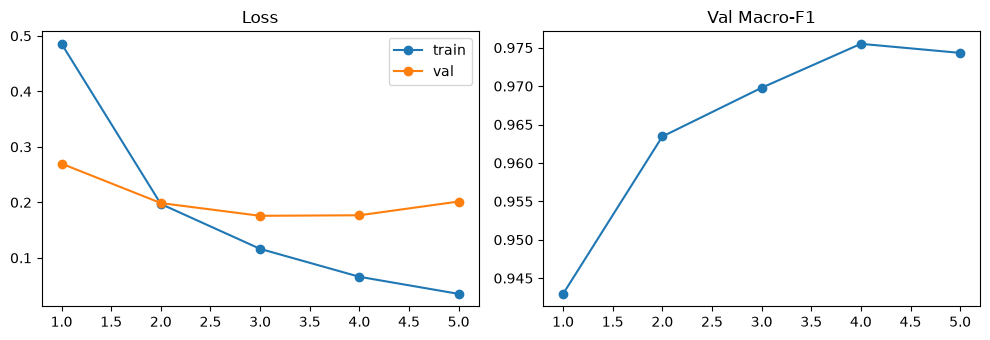

In [6]:
enc_params = list(model.encoder.parameters())
head_params = [p for n, p in model.named_parameters() if not n.startswith("encoder.")]
optimizer = torch.optim.AdamW([
    {"params": enc_params, "lr": ENCODER_LR},
    {"params": head_params, "lr": HEAD_LR}], weight_decay=WEIGHT_DECAY)
total_steps = len(train_dl) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
use_amp = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
criterion = nn.CrossEntropyLoss()
BEST_PATH = os.path.join(OUT_DIR, "phobert_crossattn_best.pt")

def move_batch(b): return {k: v.to(DEVICE, non_blocking=True) for k, v in b.items()}
def forward_batch(b):
    return model(b["text_input_ids"], b["text_attention_mask"], b["quote_input_ids"], b["quote_attention_mask"], b["quote_present"])

@torch.no_grad()
def evaluate_loader(loader):
    model.eval(); ys, ps, tot, n = [], [], 0.0, 0
    for b in loader:
        b = move_batch(b)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            logits = forward_batch(b); loss = criterion(logits, b["labels"])
        pred = logits.argmax(1)
        tot += loss.item() * len(pred); n += len(pred)
        ys.extend(b["labels"].cpu().tolist()); ps.extend(pred.cpu().tolist())
    return tot / max(n, 1), np.array(ys), np.array(ps)

history, best_f1 = [], -1.0
for epoch in range(1, EPOCHS + 1):
    model.train(); run, seen, t0 = 0.0, 0, time.time()
    for step, b in enumerate(train_dl, 1):
        b = move_batch(b)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            loss = criterion(forward_batch(b), b["labels"])
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        run += loss.item() * len(b["labels"]); seen += len(b["labels"])
        if step % 200 == 0: print(f"Epoch {epoch} step {step}/{len(train_dl)} loss={run / seen:.4f}")
    vl, yv, pv = evaluate_loader(val_dl)
    vf1 = f1_score(yv, pv, average="macro", zero_division=0)
    row = {"epoch": epoch, "train_loss": run / seen, "val_loss": vl,
           "val_acc": accuracy_score(yv, pv), "val_macro_f1": vf1, "seconds": time.time() - t0}
    history.append(row); print(row)
    if vf1 > best_f1:
        best_f1 = vf1
        torch.save({"model_state_dict": model.state_dict(), "model_name": MODEL_NAME, "label_to_id": LABEL_TO_ID,
                    "max_text_len": MAX_TEXT_LEN, "max_quote_len": MAX_QUOTE_LEN, "dropout": DROPOUT,
                    "attn_dropout": ATTN_DROPOUT, "num_heads": NUM_HEADS, "epoch": epoch, "val_macro_f1": vf1,
                    "architecture": "PhoBERT_SharedEncoder_CrossAttention_Level3"}, BEST_PATH)
        tokenizer.save_pretrained(os.path.join(OUT_DIR, "tokenizer"))
        print("Saved best checkpoint:", BEST_PATH)

hist_df = pd.DataFrame(history)
hist_df.to_csv(os.path.join(OUT_DIR, "training_history_crossattn.csv"), index=False)
display(hist_df); print("Best validation Macro-F1:", best_f1)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist_df.epoch, hist_df.train_loss, marker="o", label="train"); ax[0].plot(hist_df.epoch, hist_df.val_loss, marker="o", label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist_df.epoch, hist_df.val_macro_f1, marker="o"); ax[1].set_title("Val Macro-F1")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "training_curves_crossattn.png"), dpi=150); plt.show()

## 6. Đánh giá trên test set

Best epoch: 4 | val Macro-F1: 0.9755040903329877

===== CHỈ SỐ CỦA CHECKPOINT TỐT NHẤT TRÊN TEST SET =====
{
  "model": "PhoBERT_SharedEncoder_CrossAttention_Level3",
  "checkpoint_epoch": 4,
  "test_loss": 0.23198785791155424,
  "accuracy": 0.9688109161793372,
  "macro_f1": 0.9680629503285868,
  "weighted_f1": 0.9688179751270213
}
F1 tổng (Macro-F1): 0.9681
F1 tổng (Weighted-F1): 0.9688
F1 từng lớp:
  clean: 0.9737
  offensive: 0.9586
  hate: 0.9718


,precision,recall,f1-score,support
clean,0.977720,0.969776,0.973731,3077.000000
offensive,0.957838,0.959394,0.958615,1847.000000
hate,0.963317,0.980519,0.971842,1232.000000
accuracy,0.968811,0.968811,0.968811,0.968811
macro avg,0.966292,0.969896,0.968063,6156.000000
weighted avg,0.968872,0.968811,0.968818,6156.000000


,clean,offensive,hate
clean,2984,67,26
offensive,55,1772,20
hate,13,11,1208


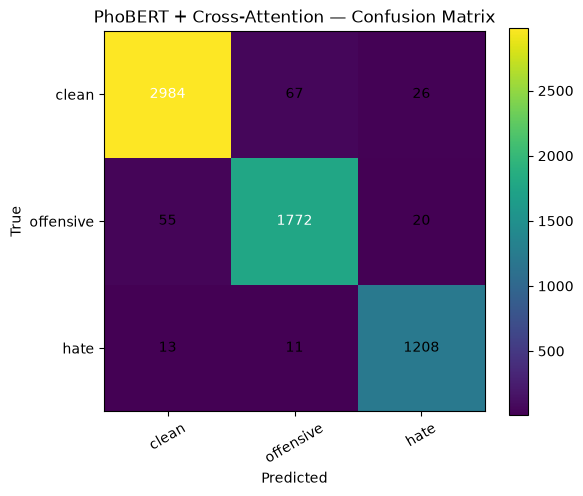

,model,accuracy,macro_f1,weighted_f1
0,PhoBERT_SharedDualBranch_Fusion,0.915138,0.911743,0.914791
1,PhoBERT_SharedEncoder_CrossAttention_Level3,0.968811,0.968063,0.968818
2,Delta (CrossAttn - Fusion),0.053673,0.056320,0.054027


,group,n,accuracy,macro_f1
0,không quote,2618,0.96715,0.966899
1,có quote,3538,0.97004,0.968972


,text,quoted_text,true_label,predicted_label
48,Làm gì có sản xuất anh ơi. Anh nghĩ sao EU giờ...,"Far Kael said: 3 EUR là phí ""tạm"" trong lúc kh...",hate,offensive
90,Bs khựa thì nói mẹ đi Sent using vozFApp,,offensive,hate
105,Các ông cho tôi xin quả Mã mời của thằng v571....,,clean,offensive
132,"Muốn số liệu thì có gì khó, nhưng tôi chỉ kiếm...",tranhung_hn3 said: Thế thì anh phải đưa ra số ...,hate,clean
167,"thằng chóa, mày nỡ lòng nào giết Hạt Tiêu",Xa Bao Son said: ông này là Hạ Tân à,clean,offensive
176,"E cần tư vấn 1 màn hình 2tr chủ yếu để code, t...",,clean,offensive
248,Phải cái clip 4 em trong đó có em mặc áo ngực ...,,clean,offensive
381,"mắt bạn bị làm sao ấy tôi thấy nó dẹp vloz, đẹ...",,clean,offensive
384,"Đóng hết, có ổ cờ bạc nào mà bọn công an phườn...",vitconchetduoi said: thì không đóng nên mới th...,clean,offensive
440,đã nhảy nợ xấu thì không còn như xưa mà đáo hạ...,,clean,hate


In [7]:
ckpt = torch.load(BEST_PATH, map_location=DEVICE)
model.load_state_dict(ckpt["model_state_dict"])
print("Best epoch:", ckpt["epoch"], "| val Macro-F1:", ckpt["val_macro_f1"])
test_loss, y_true, y_pred = evaluate_loader(test_dl)
names = [ID_TO_LABEL[i] for i in range(3)]
metrics = {"model": "PhoBERT_SharedEncoder_CrossAttention_Level3", "checkpoint_epoch": int(ckpt["epoch"]),
           "test_loss": float(test_loss), "accuracy": float(accuracy_score(y_true, y_pred)),
           "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
           "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0))}
print("\n===== CHỈ SỐ CỦA CHECKPOINT TỐT NHẤT TRÊN TEST SET =====")
print(json.dumps(metrics, ensure_ascii=False, indent=2))
print(f"F1 tổng (Macro-F1): {metrics['macro_f1']:.4f}")
print(f"F1 tổng (Weighted-F1): {metrics['weighted_f1']:.4f}")
print("F1 từng lớp:")
for _name in [ID_TO_LABEL[i] for i in range(3)]:
    _f1 = f1_score(y_true, y_pred, labels=[LABEL_TO_ID[_name]], average="micro", zero_division=0)
    print(f"  {_name}: {_f1:.4f}")
json.dump(metrics, open(os.path.join(OUT_DIR, "test_metrics_crossattn.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=2)

report_df = pd.DataFrame(classification_report(y_true, y_pred, labels=[0, 1, 2], target_names=names, output_dict=True, zero_division=0)).T
display(report_df); report_df.to_csv(os.path.join(OUT_DIR, "classification_report_crossattn.csv"), encoding="utf-8-sig")

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
cm_df = pd.DataFrame(cm, index=names, columns=names); display(cm_df)
cm_df.to_csv(os.path.join(OUT_DIR, "confusion_matrix_crossattn.csv"), encoding="utf-8-sig")
plt.figure(figsize=(6, 5)); plt.imshow(cm, interpolation="nearest"); plt.colorbar()
plt.xticks(range(3), names, rotation=30); plt.yticks(range(3), names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("PhoBERT + Cross-Attention — Confusion Matrix")
for i in range(3):
    for j in range(3): plt.text(j, i, str(cm[i, j]), ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "confusion_matrix_crossattn.png"), dpi=160); plt.show()

# So sánh với baseline Fusion
cmp_df = pd.DataFrame([BASELINE, metrics])[["model", "accuracy", "macro_f1", "weighted_f1"]]
cmp_df.loc[len(cmp_df)] = ["Delta (CrossAttn - Fusion)"] + [metrics[k] - BASELINE[k] for k in ["accuracy", "macro_f1", "weighted_f1"]]
display(cmp_df); cmp_df.to_csv(os.path.join(OUT_DIR, "comparison_vs_fusion.csv"), index=False, encoding="utf-8-sig")

# Phân tích theo nhóm có / không có quote
pred_df = test_df.copy().reset_index(drop=True)
pred_df["true_label"] = [ID_TO_LABEL[int(x)] for x in y_true]
pred_df["predicted_label"] = [ID_TO_LABEL[int(x)] for x in y_pred]
pred_df["correct"] = pred_df["true_label"] == pred_df["predicted_label"]
pred_df["has_quote"] = pred_df[QUOTE_COL].str.strip() != ""
rows = []
for flag, grp in pred_df.groupby("has_quote"):
    yt, yp = grp["label"].values, np.array([LABEL_TO_ID[x] for x in grp["predicted_label"]])
    rows.append({"group": "có quote" if flag else "không quote", "n": len(grp), "accuracy": accuracy_score(yt, yp),
                 "macro_f1": f1_score(yt, yp, average="macro", zero_division=0)})
sub_df = pd.DataFrame(rows); display(sub_df)
sub_df.to_csv(os.path.join(OUT_DIR, "subgroup_quote_analysis.csv"), index=False, encoding="utf-8-sig")

pred_df.to_csv(os.path.join(OUT_DIR, "test_predictions_crossattn.csv"), index=False, encoding="utf-8-sig")
display(pred_df.loc[~pred_df["correct"], [TEXT_COL, QUOTE_COL, "true_label", "predicted_label"]].head(30))

## 7. Trực quan hóa trọng số cross-attention (tùy chọn)
Hiển thị token của `quote` mà `text` chú ý nhiều nhất trên vài mẫu test có quote (trung bình các head, trung bình theo token text).

In [8]:
@torch.no_grad()
def top_attended_quote_tokens(idx, k=5):
    model.eval()
    b = move_batch({kk: v.unsqueeze(0) for kk, v in test_ds[idx].items()})
    logits, w_t2q, _ = model(b["text_input_ids"], b["text_attention_mask"], b["quote_input_ids"],
                             b["quote_attention_mask"], b["quote_present"], return_attn=True)
    tmask = b["text_attention_mask"][0].bool()
    w = w_t2q[0][tmask].mean(0)                         # (quote_len,)
    qmask = b["quote_attention_mask"][0].bool()
    w = w.masked_fill(~qmask, 0)
    toks = tokenizer.convert_ids_to_tokens(b["quote_input_ids"][0].cpu())
    top = torch.topk(w, min(k, int(qmask.sum()))).indices.cpu().tolist()
    return ID_TO_LABEL[int(logits.argmax(1))], [(toks[i], round(float(w[i]), 4)) for i in top]

shown = 0
for i in np.where(pred_df["has_quote"].values)[0][:200]:
    pl, top = top_attended_quote_tokens(int(i))
    print(f"[{i}] true={pred_df.true_label[i]} pred={pl}\n  text : {pred_df[TEXT_COL][i][:120]}\n  attended quote tokens: {top}\n")
    shown += 1
    if shown >= 5: break

[1] true=hate pred=hate
  text : Thời điểm đó cả ở TQ và VN đều gọi người Mông Cổ là Thát, do trước đó ở thảo nguyên Mông Cổ thì người Tatar này là nhóm 
  attended quote tokens: [('người', 0.0395), (')', 0.039), ('vì', 0.0386), ('các', 0.0383), ('người', 0.0359)]

[2] true=clean pred=clean
  text : oke anh, 1-0 cho rge
  attended quote tokens: [('is@@', 0.3018), ('da@@', 0.1321), ('sa@@', 0.1125), ('id', 0.0731), ('l', 0.0595)]

[4] true=clean pred=clean
  text : Thằng nhóc nhà fen sắp lên lớp 1 thì cũng 5 tuổi rồi, khó uốn nắn hơn mấy đứa 3 tuổi. Thằng nhóc nhà tôi hồi trước còn d
  attended quote tokens: [('Dang@@', 0.1606), ('Mi@@', 0.1008), ('xì_dầu', 0.0804), ('06@@', 0.071), ('sa@@', 0.0555)]

[5] true=hate pred=hate
  text : khó gì, cứ cuối ngày mà không có xác nhận KIA thì ting ting thôi, trước đọc tin tuyển lính đánh thuê của thằng nào chạy 
  attended quote tokens: [('in', 0.0825), ('ra', 0.072), ('ra', 0.0639), ('ra', 0.0615), ('sáng', 0.0596)]

[6] true=offensive pred=offe

## 8. Hàm dự đoán nhanh (dùng cho extension)

In [9]:
@torch.no_grad()
def predict(text, quote=""):
    model.eval()
    ts, qs = segment_text(text), segment_text(quote)
    t = tokenizer(ts, max_length=MAX_TEXT_LEN, truncation=True, padding="max_length", return_tensors="pt")
    q = tokenizer(qs, max_length=MAX_QUOTE_LEN, truncation=True, padding="max_length", return_tensors="pt")
    present = torch.tensor([float(bool(quote.strip()))])
    logits = model(t["input_ids"].to(DEVICE), t["attention_mask"].to(DEVICE),
                   q["input_ids"].to(DEVICE), q["attention_mask"].to(DEVICE), present.to(DEVICE))
    prob = torch.softmax(logits.float(), -1)[0].cpu().numpy()
    return {ID_TO_LABEL[i]: float(prob[i]) for i in range(3)}

print(predict("Mày ngu vãi", "abc said: tôi nghĩ vậy"))
print("Output dir:", OUT_DIR)

{'clean': 3.466404763230457e-08, 'offensive': 0.9999960660934448, 'hate': 3.932137587980833e-06}
Output dir: H:\Data\result\phobert_cross_attention


## Ghi chú báo cáo
- Mô hình: **shared PhoBERT encoder + cross-attention hai chiều (text↔quote) + MLP**; khác baseline Fusion ở chỗ tương tác ở mức token thay vì chỉ ghép vector `[CLS]`.
- Dùng đúng split train/val/test của baseline; kiểm tra bằng `splits/split_fingerprints.json` (so sánh với fingerprint của notebook baseline nếu cần).
- So sánh công bằng: cùng split, cùng word segmentation, chọn checkpoint theo val Macro-F1. Lưu ý notebook này dùng 5 epoch và lr riêng cho head, nên để ablation sạch có thể chạy thêm cấu hình 4 epoch.
- Nên chạy nhiều seed (ví dụ 3) và báo cáo mean ± std, vì chênh lệch nhỏ giữa hai mô hình có thể nằm trong nhiễu.
- Chỉ dùng `quoted_text` nếu ngữ cảnh đó có sẵn khi extension phân loại bình luận; cân nhắc split theo thread để tránh rò rỉ dữ liệu.

## Retrain cuối cùng trên toàn bộ dữ liệu

Cell này huấn luyện **một mô hình mới từ checkpoint tiền huấn luyện**, trên `train + val + test`, trong số epoch bằng epoch tốt nhất đã chọn ở validation. File lưu ra chỉ dùng triển khai/inference.

**Lưu ý phương pháp:** sau khi đưa `test` vào huấn luyện, không được dùng lại tập này để báo cáo kết quả test độc lập. Hãy báo cáo chỉ số ở cell đánh giá checkpoint tốt nhất *trước khi chạy cell retrain này*. Nếu cần đánh giá khoa học không thiên lệch, retrain chỉ trên `train + val` và giữ `test` hoàn toàn riêng.

In [10]:
# Gộp toàn bộ dữ liệu đã word-segmented
all_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
all_ds = FusionDataset(all_df)
all_dl = DataLoader(
    all_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    pin_memory=DEVICE.type == "cuda",
    generator=torch.Generator().manual_seed(SEED)
)

best_ckpt = torch.load(BEST_PATH, map_location="cpu")
RETRAIN_EPOCHS = int(best_ckpt["epoch"])
del best_ckpt

retrain_model = PhoBERTCrossAttention(
    MODEL_NAME, 3, NUM_HEADS, ATTN_DROPOUT, DROPOUT
).to(DEVICE)
enc_params = list(retrain_model.encoder.parameters())
head_params = [p for n, p in retrain_model.named_parameters() if not n.startswith("encoder.")]
retrain_optimizer = torch.optim.AdamW(
    [{"params": enc_params, "lr": ENCODER_LR},
     {"params": head_params, "lr": HEAD_LR}],
    weight_decay=WEIGHT_DECAY
)
total_steps = len(all_dl) * RETRAIN_EPOCHS
retrain_scheduler = get_linear_schedule_with_warmup(
    retrain_optimizer, int(WARMUP_RATIO * total_steps), total_steps
)
retrain_scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
criterion = nn.CrossEntropyLoss()

for epoch in range(1, RETRAIN_EPOCHS + 1):
    retrain_model.train()
    running_loss, seen = 0.0, 0
    for step, batch in enumerate(all_dl, 1):
        batch = {k: v.to(DEVICE, non_blocking=True) for k, v in batch.items()}
        retrain_optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            logits = retrain_model(
                batch["text_input_ids"], batch["text_attention_mask"],
                batch["quote_input_ids"], batch["quote_attention_mask"],
                batch["quote_present"]
            )
            loss = criterion(logits.float(), batch["labels"])
        retrain_scaler.scale(loss).backward()
        retrain_scaler.unscale_(retrain_optimizer)
        torch.nn.utils.clip_grad_norm_(retrain_model.parameters(), 1.0)
        retrain_scaler.step(retrain_optimizer)
        retrain_scaler.update()
        retrain_scheduler.step()
        running_loss += loss.item() * len(batch["labels"])
        seen += len(batch["labels"])
    print(f"Retrain epoch {epoch}/{RETRAIN_EPOCHS} | loss={running_loss/max(seen,1):.4f}")

FINAL_PATH = os.path.join(OUT_DIR, "phobert_crossattn_retrained_all.pt")
torch.save({
    "model_state_dict": retrain_model.state_dict(),
    "model_name": MODEL_NAME, "label_to_id": LABEL_TO_ID,
    "id_to_label": ID_TO_LABEL, "max_text_len": MAX_TEXT_LEN,
    "max_quote_len": MAX_QUOTE_LEN, "dropout": DROPOUT,
    "attn_dropout": ATTN_DROPOUT, "num_heads": NUM_HEADS,
    "retrain_epochs": RETRAIN_EPOCHS, "training_rows": len(all_ds),
    "architecture": "PhoBERT_SharedEncoder_CrossAttention_Level3"
}, FINAL_PATH)
tokenizer.save_pretrained(os.path.join(OUT_DIR, "tokenizer_retrained_all"))
print("Đã lưu mô hình retrain:", FINAL_PATH)


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 53839.03it/s]
[transformers] RobertaModel LOAD REPORT from: vinai/phobert-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.decoder.weight    | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.decoder.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Retrain epoch 1/4 | loss=0.4401
Retrain epoch 2/4 | loss=0.1761
Retrain epoch 3/4 | loss=0.0958
Retrain epoch 4/4 | loss=0.0529
Đã lưu mô hình retrain: H:\Data\result\phobert_cross_attention\phobert_crossattn_retrained_all.pt
